# Hotel Price Intelligence
## A guided Python learning notebook for Yosef

Use the PDF as your book and this notebook as your lab. All data is fictional.
Start with a 24-offer teaching fixture (26 raw rows after duplicates). The 1,000-offer modular project is the capstone, not a completed deliverable here.

**Six stages:** foundations → inspection → cleaning → comparisons → relationships → explanation.
Run cells in order. Exercise cells are comment-only until you fill them in. The worked examples run without solving the exercises.

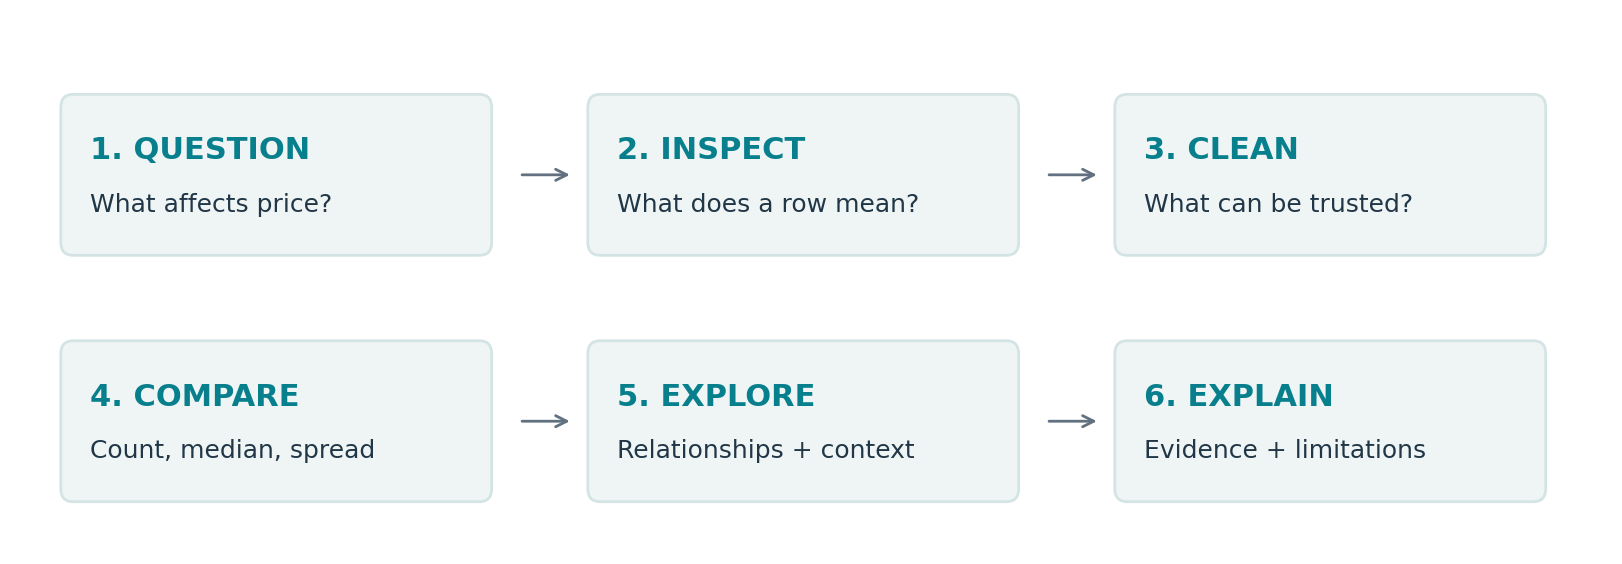

## Setup
Install Python 3.12, VS Code, and Microsoft's Python and Jupyter extensions.
Extract the ZIP and open its folder. In the Windows PowerShell terminal:
```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
```
On macOS/Linux:
```bash
python3.12 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt
```
Then select the `.venv` notebook kernel. If you downloaded this notebook alone, use the same commands with the following packages instead of `-r requirements.txt`:
`numpy==2.3.5 pandas==2.2.3 matplotlib==3.10.8 seaborn==0.13.2 scipy==1.17.0 ipykernel`.
The first package installation needs internet. The lessons use local data only.

In [22]:
import sys
import numpy as np
print("Python:", sys.version.split()[0])
print("Kernel:", sys.executable)

Python: 3.14.6
Kernel: D:\anaconda\python.exe


## Stage 1 · Python foundations
**Learn:** variables, types, lists, dictionaries, loops and functions.
**Predict:** what will the next cell print? See PDF pages 6-8 for the syntax explanations.

In [21]:
hotel_name = "Paris Practice Hotel 1"
price_eur = 145.0
nights = 3
is_available = True
total = price_eur * nights
print(f"{hotel_name}: EUR {total:.2f}")

Paris Practice Hotel 1: EUR 435.00


### Your turn · Exercise 01
Add a Markdown explanation of what one row in the hotel dataset represents.

**Hint:** A room offering in a month; hotel IDs may repeat.

In [ ]:
# Exercise 01: write your code here.
# Explain your result in a Markdown cell below.
# hello i am yosef

hello


### Your turn · Exercise 02
Calculate four nights at EUR 120 per night with a 10% discount.

**Hint:** Use total * (1 - discount) and format with :.2f.

In [4]:
# Exercise 02: write your code here.
# Explain your result in a Markdown cell below.

In [46]:
offer = {"city": "Lyon", "price_eur": 85.0, "stars": 3}
prices = [85.0, 130.0, 120.0]
print(offer["city"])
print(prices[0])
for price in prices:
    if price < 100:
        print(f"Budget offer: EUR {price:.2f}")

four = {prices[2]-(prices[2]*10)/100}
num = 4
for n in four
    four*=n
print(total)

SyntaxError: expected ':' (3579152485.py, line 11)

### Your turn · Exercise 03
Create three offer dictionaries and print only those priced below EUR 150.

**Hint:** Loop over the list and inspect each price_eur value.

In [6]:
# Exercise 03: write your code here.
# Explain your result in a Markdown cell below.

In [7]:
def stay_cost(price_eur, nights, discount=0.0):
    if price_eur <= 0 or nights <= 0:
        raise ValueError("Price and nights must be positive")
    if not 0 <= discount <= 1:
        raise ValueError("Discount must be between 0 and 1")
    return price_eur * nights * (1 - discount)

print(stay_cost(120.0, 4, discount=0.10))
assert stay_cost(100, 2) == 200
assert np.isclose(stay_cost(120, 4, .10), 432)

432.0


### Your turn · Exercise 04
Write price_per_m2(price_eur, room_size_m2). Reject a nonpositive size.

**Hint:** 100 / 20 should return 5.

In [8]:
# Exercise 04: write your code here.
# Explain your result in a Markdown cell below.

## Stage 2 · Load and inspect
**Learn:** CSV files, DataFrames, Series, schema, masks and missing-value inspection.
The fixture has 12 hotels with two offers each. January is Standard, July is Deluxe: these are confounded in this small sample.
The next cell creates the practice CSV **only if it does not already exist**, then loads it.
If you edit that file, later fixture-specific answer counts may differ. Back up edits before restoring the original.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Six cities, two fictional hotels per city, two offers per hotel.
cities = ["Paris", "Lyon", "Nice", "Lille", "Marseille", "Bordeaux"]
base_prices = [145, 85, 120, 75, 90, 100]
records = []
for city_i, city in enumerate(cities):
    for hotel_i in range(2):
        for month, room_type in [(1, "Standard"), (7, "Deluxe")]:
            summer = month == 7
            records.append({
                "hotel_id": 1001 + city_i * 2 + hotel_i,
                "hotel_name": f"{city} Practice Hotel {hotel_i + 1}",
                "city": city,
                "star_rating": 3 + hotel_i,
                "guest_rating": round(7.3 + .6 * hotel_i + .1 * city_i, 1),
                "room_size_m2": 20.0 + 7 * hotel_i + 8 * summer,
                "room_type": room_type,
                "month": month,
                "distance_center_km": 1.2 + 2.0 * hotel_i,
                "price_eur": float(base_prices[city_i] + 45 * hotel_i
                                   + 35 * summer),
            })
practice = pd.DataFrame(records)
practice.loc[[3, 17], "guest_rating"] = np.nan
practice.loc[[7, 20], "room_size_m2"] = np.nan
practice.loc[8, "price_eur"] = -45.0    # Deliberately invalid
practice.loc[23, "price_eur"] = 750.0  # Unusual, not proven wrong
raw = pd.concat([practice, practice.iloc[[0, 15]]], ignore_index=True)
data_dir = Path("practice_data")
data_dir.mkdir(exist_ok=True)
raw_path = data_dir / "hotels_practice_raw.csv"
if not raw_path.exists():
    raw.to_csv(raw_path, index=False)
raw = pd.read_csv(raw_path)  # Later lessons start from the saved CSV.
print(f"Loaded {len(raw)} practice rows from {raw_path}")

Loaded 26 practice rows from practice_data/hotels_practice_raw.csv


In [10]:
required_columns = [
    "hotel_id", "hotel_name", "city", "star_rating", "guest_rating",
    "room_size_m2", "room_type", "month", "distance_center_km", "price_eur",
]
print(raw.shape)
display(raw.head(3))
print(raw.dtypes)
print(raw.isna().sum())
print("Duplicate full rows:", raw.duplicated().sum())
display(raw["price_eur"].describe())

(26, 10)
hotel_id                int64
hotel_name             object
city                   object
star_rating             int64
guest_rating          float64
room_size_m2          float64
room_type              object
month                   int64
distance_center_km    float64
price_eur             float64
dtype: object
hotel_id              0
hotel_name            0
city                  0
star_rating           0
guest_rating          2
room_size_m2          2
room_type             0
month                 0
distance_center_km    0
price_eur             0
dtype: int64
Duplicate full rows: 2


,hotel_id,hotel_name,city,star_rating,guest_rating,room_size_m2,room_type,month,distance_center_km,price_eur
0,1001,Paris Practice Hotel 1,Paris,3,7.3,20.0,Standard,1,1.2,145.0
1,1001,Paris Practice Hotel 1,Paris,3,7.3,28.0,Deluxe,7,1.2,180.0
2,1002,Paris Practice Hotel 2,Paris,4,7.9,27.0,Standard,1,3.2,190.0


,price_eur
count,26.000000
mean,158.653846
std,130.924083
min,-45.000000
25%,120.000000
50%,145.000000
75%,165.000000
max,750.000000


### Your turn · Exercise 05
Count raw rows and distinct hotel IDs. Explain the difference.

**Hint:** len(raw), raw["hotel_id"].nunique().

In [11]:
# Exercise 05: write your code here.
# Explain your result in a Markdown cell below.

### Your turn · Exercise 06
Count missing values and duplicate full rows. Write a sentence about each issue.

**Hint:** NaN and a negative price are different issues.

In [12]:
# Exercise 06: write your code here.
# Explain your result in a Markdown cell below.

In [13]:
budget = raw.loc[
    (raw["price_eur"] > 0) & (raw["price_eur"] < 150),
    ["hotel_name", "city", "price_eur"],
]
display(budget.sort_values("price_eur").head())

,hotel_name,city,price_eur
12,Lille Practice Hotel 1,Lille,75.0
4,Lyon Practice Hotel 1,Lyon,85.0
16,Marseille Practice Hotel 1,Marseille,90.0
20,Bordeaux Practice Hotel 1,Bordeaux,100.0
13,Lille Practice Hotel 1,Lille,110.0


### Your turn · Exercise 07
Show Lyon offers with valid prices below EUR 150. Select city, room_type and price_eur.

**Hint:** Use parenthesized masks joined with &.

In [14]:
# Exercise 07: write your code here.
# Explain your result in a Markdown cell below.

## Stage 3 · Clean and validate
**Policy:** full-row duplicates removed; legitimate repeated IDs retained; missing ratings and sizes preserved; invalid prices separated; unusual prices flagged and retained.
The original `raw` table is never changed by the cleaning cells.

In [15]:
missing_columns = set(required_columns) - set(raw.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")
dedup = raw.drop_duplicates().copy()
print("Rows before:", len(raw), "after deduplication:", len(dedup))

Rows before: 26 after deduplication: 24


### Your turn · Exercise 08
Report the number of duplicate copies removed.

**Hint:** Use the before-and-after row counts.

In [16]:
# Exercise 08: write your code here.
# Explain your result in a Markdown cell below.

In [17]:
dedup["price_eur"] = pd.to_numeric(dedup["price_eur"], errors="coerce")
price_ok = np.isfinite(dedup["price_eur"]) & dedup["price_eur"].gt(0)
rejected = dedup.loc[~price_ok].copy()
clean = dedup.loc[price_ok].copy()
print("Valid-price rows:", len(clean), "rejected rows:", len(rejected))
display(rejected)

Valid-price rows: 23 rejected rows: 1


,hotel_id,hotel_name,city,star_rating,guest_rating,room_size_m2,room_type,month,distance_center_km,price_eur
8,1005,Nice Practice Hotel 1,Nice,3,7.5,20.0,Standard,1,1.2,-45.0


### Your turn · Exercise 09
Apply the validity rule to [100, 0, -5, NaN, infinity].

**Hint:** Use a Pandas Series and np.isfinite().

In [18]:
# Exercise 09: write your code here.
# Explain your result in a Markdown cell below.

In [19]:
q1, q3 = clean["price_eur"].quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
clean["price_outlier"] = ~clean["price_eur"].between(lower, upper)
print("Screening fences:", lower, upper)
display(clean.loc[clean["price_outlier"], ["city", "price_eur"]])

Screening fences: 48.75 238.75


,city,price_eur
23,Bordeaux,750.0


### Your turn · Exercise 10
Compare mean and median with and without flagged prices.

**Hint:** Use clean.loc[~clean["price_outlier"]].

In [20]:
# Exercise 10: write your code here.
# Explain your result in a Markdown cell below.

In [21]:
assert len(raw) == len(dedup) + raw.duplicated().sum()
assert len(dedup) == len(clean) + len(rejected)
assert not clean[required_columns].duplicated().any()
assert np.isfinite(clean["price_eur"]).all()
assert clean["price_eur"].gt(0).all()
clean.to_csv(data_dir / "hotels_practice_cleaned.csv", index=False)
rejected.to_csv(data_dir / "hotels_practice_rejected.csv", index=False)
print("Checks passed. Separate cleaned and rejected CSVs saved.")

Checks passed. Separate cleaned and rejected CSVs saved.


### Your turn · Exercise 11
Explain why deduplication normally precedes row-specific derived fields.

**Hint:** Different derived values can obscure identical source rows.

In [22]:
# Exercise 11: write your code here.
# Explain your result in a Markdown cell below.

## Stage 4 · Compare and visualize
**Learn:** mean, median, count, spread, groupby and four core chart types.
Every chart should state units and its population. These charts use the valid-price table and retain flagged prices.

In [23]:
summary = clean.groupby("city")["price_eur"].agg(
    offers="count", mean="mean", median="median", lowest="min", highest="max"
)
display(summary.round(2))

,offers,mean,median,lowest,highest
city,,,,,
Bordeaux,4,282.50,140.0,100.0,750.0
Lille,4,115.00,115.0,75.0,155.0
Lyon,4,125.00,125.0,85.0,165.0
Marseille,4,130.00,130.0,90.0,170.0
Nice,3,173.33,165.0,155.0,200.0
Paris,4,185.00,185.0,145.0,225.0


### Your turn · Exercise 12
Sort by descending median. Which city has fewer valid offers?

**Hint:** The rejected price belongs to Nice.

In [24]:
# Exercise 12: write your code here.
# Explain your result in a Markdown cell below.

In [25]:
city_medians = clean.groupby("city")["price_eur"].median()
city_medians.sort_values().plot.barh(color="#087F8C")
plt.xlabel("Median price per night (EUR)")
plt.title("Practice sample: typical price by city (n=23 offers)")
plt.tight_layout()
plt.show()

In [26]:
clean["price_eur"].plot.hist(bins=10, color="#507CB6", edgecolor="white")
plt.xlabel("Price per night (EUR)")
plt.ylabel("Number of offers")
plt.title("Practice sample: price distribution, flagged prices included")
plt.tight_layout()
plt.show()

### Your turn · Exercise 13
Change the histogram bin count and explain what changes.

**Hint:** The data stays the same; the visual grouping changes.

In [27]:
# Exercise 13: write your code here.
# Explain your result in a Markdown cell below.

In [28]:
sns.boxplot(data=clean, x="star_rating", y="price_eur", color="#B9DADD")
plt.xlabel("Hotel star classification")
plt.ylabel("Price per night (EUR)")
plt.title("Practice sample: star classification and price")
plt.tight_layout()
plt.show()

### Your turn · Exercise 14
Count valid-price offers in each star group.

**Hint:** groupby("star_rating")["price_eur"].count().

In [29]:
# Exercise 14: write your code here.
# Explain your result in a Markdown cell below.

In [30]:
display(clean.groupby("month")["price_eur"].agg(["count", "mean", "median"]))
by_city_month = clean.groupby(["city", "month"])["price_eur"].median()
display(by_city_month.unstack("month"))

,count,mean,median
month,,,
1,11,125.454545,130.0
7,12,207.500000,160.0


month,1,7
city,,
Bordeaux,122.5,442.5
Lille,97.5,132.5
Lyon,107.5,142.5
Marseille,112.5,147.5
Nice,165.0,177.5
Paris,167.5,202.5


### Your turn · Exercise 15
Explain why month and room type cannot be separated in the practice fixture.

**Hint:** January is always Standard; July is always Deluxe.

In [31]:
# Exercise 15: write your code here.
# Explain your result in a Markdown cell below.

## Stage 5 · Explore relationships
**Learn:** complete-pair filtering, scatter plots, Pearson and Spearman correlation, sensitivity and peer-group comparisons.
Correlation is an association, not a causal effect. Synthetic patterns come from our assumptions.

In [32]:
pairs = clean[["room_size_m2", "price_eur"]].dropna()
print("Complete pairs:", len(pairs))
sns.scatterplot(data=pairs, x="room_size_m2", y="price_eur", color="#087F8C")
plt.xlabel("Room size (m²)")
plt.ylabel("Price per night (EUR)")
plt.title(f"Practice sample: size and price (n={len(pairs)})")
plt.tight_layout()
plt.show()

Complete pairs: 21


### Your turn · Exercise 16
Create a guest-rating/price scatter plot. Report the complete-pair count.

**Hint:** Drop missing values only from the two relevant fields.

In [33]:
# Exercise 16: write your code here.
# Explain your result in a Markdown cell below.

In [34]:
pearson_r = pairs["room_size_m2"].corr(pairs["price_eur"])
spearman_r = pairs["room_size_m2"].corr(pairs["price_eur"], method="spearman")
print(f"n={len(pairs)}, Pearson={pearson_r:.3f}, Spearman={spearman_r:.3f}")

n=21, Pearson=0.502, Spearman=0.635


### Your turn · Exercise 17
Compute Pearson r with and without flagged prices; report both pair counts.

**Hint:** Filter outliers before dropping missing size/price pairs.

In [35]:
# Exercise 17: write your code here.
# Explain your result in a Markdown cell below.

In [36]:
cols = ["price_eur", "star_rating", "guest_rating", "room_size_m2", "distance_center_km"]
numeric = clean[cols]
corr = numeric.corr(min_periods=3)
present = numeric.notna().astype(int)
pair_counts = present.T.dot(present)
display(pair_counts)
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="BrBG")
plt.title("Practice sample: pairwise Pearson correlation")
plt.tight_layout()
plt.show()

,price_eur,star_rating,guest_rating,room_size_m2,distance_center_km
price_eur,23,23,21,21,23
star_rating,23,23,21,21,23
guest_rating,21,21,21,19,21
room_size_m2,21,21,19,21,21
distance_center_km,23,23,21,21,23


### Your turn · Exercise 18
Read the guest-rating/room-size pair count and explain it.

**Hint:** Both values must be recorded in the same row.

In [37]:
# Exercise 18: write your code here.
# Explain your result in a Markdown cell below.

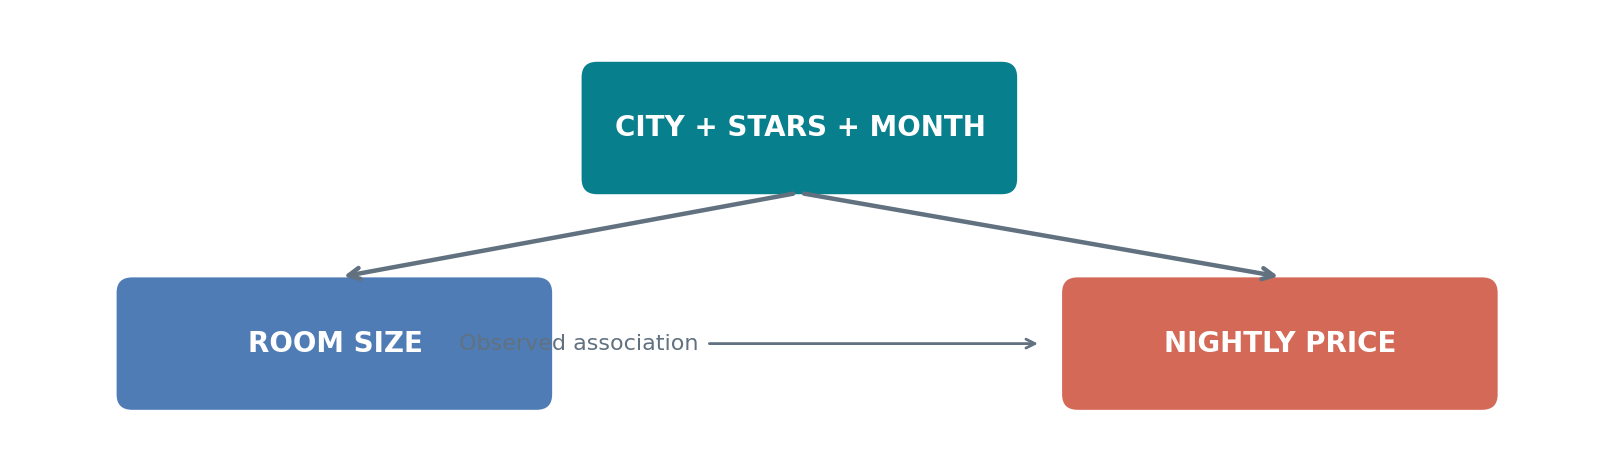

In [38]:
peer_keys = ["city", "star_rating", "room_type", "month"]
groups = clean.groupby(peer_keys)["price_eur"]
clean["peer_count"] = groups.transform("size")
clean["peer_median"] = groups.transform("median")
clean["price_vs_peer"] = clean["price_eur"] / clean["peer_median"]
candidates = clean.loc[
    (clean["peer_count"] >= 5)
    & (clean["guest_rating"] >= 8)
    & (clean["price_vs_peer"] < 1)
]
if candidates.empty:
    print("No candidates meet the screen. Practice peer groups are too small.")
else:
    display(candidates)

No candidates meet the screen. Practice peer groups are too small.


### Your turn · Exercise 19
Explain two missing factors in the candidate screen and why an empty result is valid.

**Hint:** No peer group reaches five offers. Consider terms, taxes or amenities.

In [39]:
# Exercise 19: write your code here.
# Explain your result in a Markdown cell below.

## Stage 6 · Explain and complete
**Learn:** writing a claim with evidence, reporting limitations and reproducing an analysis.
Use the finding template: question → population → statistic/chart → interpretation → limitation.

### Your turn · Exercise 20
Write three original findings in Markdown, each with a measure and a limitation.

**Hint:** Read PDF page 25 for a template; compute your own numbers.

In [40]:
# Exercise 20: write your code here.
# Explain your result in a Markdown cell below.

### My findings
Replace the prompts below with your explanations.

1. **Cleaning:** population, row-count change and missing-value policy.
2. **Price comparison:** statistic, group count and unusual-value sensitivity.
3. **Relationship:** coefficient, pair count, comparison and limitation.

### Your turn · Exercise 21
Plan your 1,000-base-offer capstone generation formula and five validation checks.

**Hint:** See PDF page 26. Define parameters as synthetic assumptions; keep hotel-level attributes stable.

In [41]:
# Exercise 21: write your code here.
# Explain your result in a Markdown cell below.

### Your turn · Exercise 22
Prepare a five-minute demo for Jeet.

**Hint:** Problem, data, cleaning, chart, correlation, limitation, next step.

In [42]:
# Exercise 22: write your code here.
# Explain your result in a Markdown cell below.

## Capstone checklist
- Deterministic generation of 1,000 distinct base offers, then about 20 duplicate copies.
- About 5% missing ratings, 3% missing sizes and 1% unusually high prices; document injection counts.
- A separate generator module, cleaner module, analysis notebook, README and focused tests.
- Raw preserved; invalid prices separated; missing values retained; unusual prices flagged.
- Four labelled charts, group counts, complete-pair correlations and an outlier sensitivity comparison.
- Three evidence-backed findings and a fresh-kernel run.

The capstone source modules are not included in this learning pack. Build them after mastering the examples.

# Answer notes · attempt the exercises first
The following cells give selected worked solutions. Your exercise cells are intentionally blank. The book contains explanations for all 22 exercises.

In [43]:
# Exercises 02-04
print(f"EUR {120 * 4 * .9:.2f}")
example_offers = [
    {"city": "Paris", "price_eur": 145},
    {"city": "Lyon", "price_eur": 85},
    {"city": "Nice", "price_eur": 200},
]
for item in example_offers:
    if item["price_eur"] < 150:
        print(item)

def price_per_m2(price_eur, room_size_m2):
    if room_size_m2 <= 0:
        raise ValueError("Room size must be positive")
    return price_eur / room_size_m2

assert price_per_m2(100, 20) == 5

EUR 432.00
{'city': 'Paris', 'price_eur': 145}
{'city': 'Lyon', 'price_eur': 85}


In [44]:
# Exercises 05-09
print("Rows:", len(raw), "distinct hotels:", raw["hotel_id"].nunique())
print(raw.isna().sum())
print("Duplicate copies:", raw.duplicated().sum())
display(raw.loc[
    (raw["city"] == "Lyon") & (raw["price_eur"] > 0) & (raw["price_eur"] < 150),
    ["city", "room_type", "price_eur"],
])
values = pd.Series([100, 0, -5, np.nan, np.inf])
print("Valid:", values.loc[np.isfinite(values) & values.gt(0)].tolist())

Rows: 26 distinct hotels: 12
hotel_id              0
hotel_name            0
city                  0
star_rating           0
guest_rating          2
room_size_m2          2
room_type             0
month                 0
distance_center_km    0
price_eur             0
dtype: int64
Duplicate copies: 2
Valid: [100.0]


,city,room_type,price_eur
4,Lyon,Standard,85.0
5,Lyon,Deluxe,120.0
6,Lyon,Standard,130.0


In [45]:
# Exercises 10, 12 and 14
without_flagged = clean.loc[~clean["price_outlier"]]
display(pd.DataFrame({
    "all_valid_prices": clean["price_eur"].agg(["mean", "median"]),
    "without_flagged": without_flagged["price_eur"].agg(["mean", "median"]),
}).round(2))
display(summary.sort_values("median", ascending=False))
print(clean.groupby("star_rating")["price_eur"].count())

star_rating
3    11
4    12
Name: price_eur, dtype: int64


,all_valid_prices,without_flagged
mean,168.26,141.82
median,145.00,140.00


,offers,mean,median,lowest,highest
city,,,,,
Paris,4,185.000000,185.0,145.0,225.0
Nice,3,173.333333,165.0,155.0,200.0
Bordeaux,4,282.500000,140.0,100.0,750.0
Marseille,4,130.000000,130.0,90.0,170.0
Lyon,4,125.000000,125.0,85.0,165.0
Lille,4,115.000000,115.0,75.0,155.0


In [46]:
# Exercises 16-18
rating_pairs = clean[["guest_rating", "price_eur"]].dropna()
print("Rating/price pairs:", len(rating_pairs))
size_pairs_without = without_flagged[["room_size_m2", "price_eur"]].dropna()
print("Size/price with flagged:", len(pairs), pearson_r)
print("Size/price without flagged:", len(size_pairs_without),
      size_pairs_without["room_size_m2"].corr(size_pairs_without["price_eur"]))
print("Rating/size pairs:", pair_counts.loc["guest_rating", "room_size_m2"])

Rating/price pairs: 21
Size/price with flagged: 21 0.5024876861083126
Size/price without flagged: 20 0.7310650360217793
Rating/size pairs: 19


### Interpretation notes
- Exercise 11: row-specific fields can mask identical source rows.
- Exercise 15: month and room type always change together in this fixture.
- Exercise 19: zero candidates is expected because each detailed peer group has one offer.
- Exercises 20-22: answers depend on your explanation. Include evidence, assumptions and limitations.

## Official references
- [Python 3.12 venv](https://docs.python.org/3.12/library/venv.html)
- [VS Code Jupyter notebooks](https://code.visualstudio.com/docs/datascience/jupyter-notebooks)
- [Pandas correlation](https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.DataFrame.corr.html)
- [Seaborn boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)

Finish by restarting the kernel and running all cells. Record what you can now explain independently.